# AntM2C Dataset — Exploratory Data Analysis (EDA)

Welcome to the exploratory data analysis notebook for the **AntM2C 10M Dataset**, a large-scale **multi-scenario, multi-modal CTR prediction dataset** from real-world Alipay user interactions.

The goal of this analysis is to:

- Understand the structure and content of the dataset
- Identify potential issues like missing values or imbalances
- Explore distributions and characteristics of key features
- Prepare the dataset for downstream tasks like model training, cold-start simulations, and modality fusion

The dataset is split across three large CSV files (each  approx 24.5GB), and includes:
- **ID-based features** (`user_id`, `item_id`, `scene`)
- **Text features** (`item_title`, `query_entity_seq`, etc.)
- **CTR labels** (binary `label`: 0 = not clicked, 1 = clicked)

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import the Required Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.notebook import tqdm

# Configuration Settings
pd.set_option('display.max_columns', 100)
sns.set(style="whitegrid")

In [ ]:
# Define File Paths
csv_dir = "/content/drive/MyDrive/Final_Year_Project/Implementation/Datasets/AntM2C_10M"

file_paths = [
    os.path.join(csv_dir, f'antm2c_10m_part{i}.csv') for i in range(3)
]

# Check if files exist
for path in file_paths:
    assert os.path.exists(path), f"File not found: {path}"

In [ ]:
# Load and Concatenate CSVs (with progress)
%%time

essential_columns = [
    'user_id', 'item_id', 'scene', 'log_time', 'label',
    'item_entity_names', 'item_title', 'query_entity_seq',
    'bill_entity_seq', 'service_entity_seq'
]

dfs = []
for i, path in enumerate(file_paths):
    print(f"Loading part {i}...")
    df = pd.read_csv(path, usecols=essential_columns)
    dfs.append(df)
    break;

# Combine into one DataFrame
df_all = pd.concat(dfs, ignore_index=True)

# Preview
print("Combined Data Shape:", df_all.shape)
display(df_all.head())

Loading part 0...
Combined Data Shape: (3730329, 10)


,user_id,item_id,log_time,label,bill_entity_seq,service_entity_seq,query_entity_seq,item_entity_names,item_title,scene
0,1236562,287924,2023-07-14 00:21:44,0,"椒盐花生,油炸,收款码,移动支付,牛肉炒面,雪糕,金林饭店,青岛,柚子乌龙茶,公交,康师傅,...","营销玩法,红包,游戏玩乐,任务,现金红包,游戏,理财,抽奖,支付宝,转账,集步,现金,赚钱红...","投教基地,信用卡,月月赚,理财服务,流量卡,积分,洗衣液,电话卡,好医保,手机,花呗金,浦发...","饮用水,百岁山,天然矿泉,绿账,消费金,小瓶,付邮购",消费金-百岁山天然矿泉水整箱小瓶饮用水，绿账优淘，天然矿泉水整箱小瓶付邮购,4
1,1181655,425272,2023-07-18 12:45:30,1,"土家酱香饼,官方旗舰,miniso,湛江市,脆皮火腿肠,椰蓉酥,花呗,曼巴特购物广场,江苏,...","营销玩法,红包,任务,现金,集分宝,现金红包,做任务,现金领取,抽奖,集步,签到,打卡,领现...","中国联通,流量卡,手机号码卡,红包,电话卡,营业厅,天天集宝,腾讯,信用卡,社会保障,肯德基...","医疗,好医保,百万医疗",百万医疗免费体验,2
2,663299,604771,2023-08-01 09:28:15,1,"马桶,婚礼吊兰,资料夹,夹子,润眼液,韩国,马桶坐垫,除胶剂,帐单,大嘴猴,水果,白酒概念,...","蚂蚁森林能量,互动小游戏,公益慈善,公益种树,种树,蚂蚁庄园,营销玩法,养小鸡,喂小鸡,小鸡...","手机,境内自驾游旅行险,消费节,荣耀honor,apple,出租,支付宝,消费金,意外险,保...",商品橱窗,逛15秒商品橱窗,2
3,519271,237488,2023-08-03 23:19:06,0,NaN,NaN,NaN,"阿里宝卡,宝卡,流量卡,vip卡",中国联通营业厅电话卡,1
4,1659372,604771,2023-08-01 20:24:21,1,"转账,收款码,乌苏市,余利宝,银行卡,手机扫码支付,花呗,蚂蚁财富,帐单,通达建材商店,芭芭...","营销玩法,红包,互动小游戏,水果,果树,种果树,果农,芭芭农场,蚂蚁庄园,现金红包,养小鸡,...","健康金,里程,手机,福利金,网商银行,二手手机,免押金租赁,回收回收,火车,免费,新疆维吾尔...",商品橱窗,逛15秒商品橱窗,2


CPU times: user 3min 40s, sys: 16.1 s, total: 3min 56s
Wall time: 7min 9s


In [ ]:
#  Save to pickle after first load to reduce load time later
import pickle

pkl_path = os.path.join(csv_dir, "antm2c_10m_part0_combined.pkl")

# Use pickle if already saved
if os.path.exists(pkl_path):
    try:
        print("Loading from cache...")
        df_all = pd.read_pickle(pkl_path)
    except (EOFError, pickle.UnpicklingError):
        print("Corrupted pickle file found. Removing and recreating...")
        os.remove(pkl_path)
        print("Saving combined CSV as pickle for faster future loading...")
        df_all.to_pickle(pkl_path)
else:
    print("Saving combined CSV as pickle for faster future loading...")
    df_all.to_pickle(pkl_path)

Loading from cache...


## 1. Dataset Overview

This section provides a high-level overview of the loaded dataset, including:

- The number of rows and columns
- Data types and memory usage
- A quick look at sample records
- Missing value analysis
- Unique value counts per feature
- Distribution of the `label` column (click vs. no-click)

In [ ]:
print("Rows, Columns:", df.shape)

Rows, Columns: (3730329, 10)


In [ ]:
print(df.info(memory_usage="deep"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3730329 entries, 0 to 3730328
Data columns (total 8 columns):
 #   Column             Dtype 
---  ------             ----- 
 0   user_id            int64 
 1   item_id            int64 
 2   log_time           object
 3   label              int64 
 4   query_entity_seq   object
 5   item_entity_names  object
 6   item_title         object
 7   scene              int64 
dtypes: int64(4), object(4)
memory usage: 4.4 GB
None


In [ ]:
df.head(5)

,user_id,item_id,log_time,label,query_entity_seq,item_entity_names,item_title,scene
0,1236562,287924,2023-07-14 00:21:44,0,"投教基地,信用卡,月月赚,理财服务,流量卡,积分,洗衣液,电话卡,好医保,手机,花呗金,浦发...","饮用水,百岁山,天然矿泉,绿账,消费金,小瓶,付邮购",消费金-百岁山天然矿泉水整箱小瓶饮用水，绿账优淘，天然矿泉水整箱小瓶付邮购,4
1,1181655,425272,2023-07-18 12:45:30,1,"中国联通,流量卡,手机号码卡,红包,电话卡,营业厅,天天集宝,腾讯,信用卡,社会保障,肯德基...","医疗,好医保,百万医疗",百万医疗免费体验,2
2,663299,604771,2023-08-01 09:28:15,1,"手机,境内自驾游旅行险,消费节,荣耀honor,apple,出租,支付宝,消费金,意外险,保...",商品橱窗,逛15秒商品橱窗,2
3,519271,237488,2023-08-03 23:19:06,0,NaN,"阿里宝卡,宝卡,流量卡,vip卡",中国联通营业厅电话卡,1
4,1659372,604771,2023-08-01 20:24:21,1,"健康金,里程,手机,福利金,网商银行,二手手机,免押金租赁,回收回收,火车,免费,新疆维吾尔...",商品橱窗,逛15秒商品橱窗,2


In [ ]:
print("Data types per column:")
print(df.dtypes)

Data types per column:
user_id               int64
item_id               int64
log_time             object
label                 int64
query_entity_seq     object
item_entity_names    object
item_title           object
scene                 int64
dtype: object


In [ ]:
# Missing values
print("Missing values per column:")
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing %": missing_percent
})
missing_df[missing_df["Missing Count"] > 0].sort_values(by="Missing %", ascending=False)

Missing values per column:


,Missing Count,Missing %
query_entity_seq,111752,2.995768


In [ ]:
print("Unique value counts:")
df.nunique().sort_values(ascending=False)

Unique value counts:


,0
log_time,1777878
query_entity_seq,898813
item_entity_names,102050
user_id,67615
item_id,59142
item_title,51692
scene,5
label,2


Click label distribution:


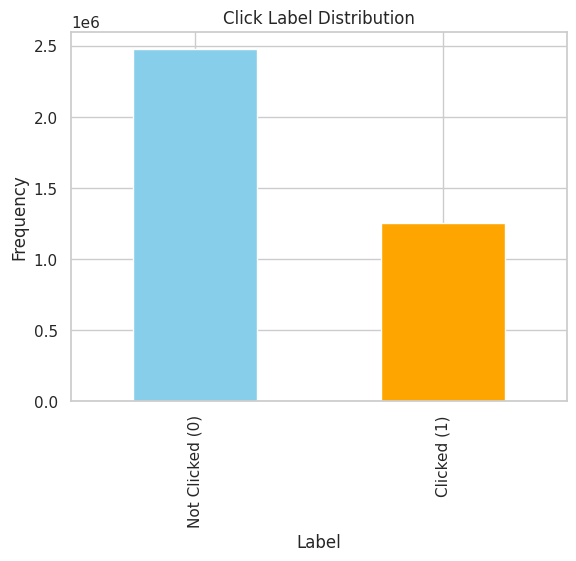

CTR = 33.63%


In [ ]:
# Value counts of target label (clicked vs. not clicked)
print("Click label distribution:")
label_counts = df["label"].value_counts().sort_index()
label_counts.plot(kind="bar", color=["skyblue", "orange"])
plt.xticks([0, 1], ["Not Clicked (0)", "Clicked (1)"])
plt.title("Click Label Distribution")
plt.xlabel("Label")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

print(f"CTR = {label_counts[1] / label_counts.sum():.2%}")

# Summary
- The part0 (subsection) dataset contains approximately 3.73 million rows and 8 columns. The columns include user and item IDs, log time, click label, text features (`query_entity_seq`, `item_entity_names`, `item_title`), and a scene identifier.

- The data types are a mix of integers and objects (strings).

- There is a small percentage of missing values (around 3%) in the `query_entity_seq` column, while other columns are complete.

- The `scene` column has 5 unique values, and the label column has 2 unique values (0 and 1 for not clicked and clicked, respectively).

- The click-through rate (CTR) is approximately 33.63%, meaning about a third of the interactions resulted in a click.

### 2.1 User Features

This section explores the features related to users in the AntM2C dataset.

- `user_id`: A unique identifier for each user
- `deep_features_0` to `deep_features_26`: Anonymized dense ID-based user features
- `query_entity_seq`, `bill_entity_seq`, `service_entity_seq`: Textual representations of recent user behavior (e.g., search terms, billing entities, services)

In [ ]:
num_users = df_all['user_id'].nunique()
print(f"Unique users: {num_users:,}")

Unique users: 67,615


In [ ]:
# User text sequence columns
text_cols = ['query_entity_seq', 'bill_entity_seq', 'service_entity_seq']

for col in text_cols:
    print(f"{col} — Missing: {df_all[col].isnull().mean():.2%}, Unique: {df_all[col].nunique():,}")

    # Token length distribution
    lengths = df_all[col].dropna().apply(lambda x: len(str(x).split(' ')))
    print(f"Avg length: {lengths.mean():.2f}, Median: {lengths.median()}, Max: {lengths.max()}")


query_entity_seq — Missing: 3.00%, Unique: 898,813
Avg length: 2.01, Median: 1.0, Max: 17
bill_entity_seq — Missing: 3.58%, Unique: 1,027,005
Avg length: 1.12, Median: 1.0, Max: 19
service_entity_seq — Missing: 4.00%, Unique: 1,042,768
Avg length: 1.00, Median: 1.0, Max: 5


### 2.2 Item Features & Other Contextual Features

This section focuses on item-related identifiers and contextual metadata that play a role in CTR prediction.

#### Item Features
- `item_id`: A unique identifier for each item
- `item_entity_names`, `item_title`: Textual descriptions used for recommendation — potentially rich in semantic information

#### Other Features
- `log_time`: Timestamp of the interaction
- `scene`: The interaction scenario (A to E)
- `label`: The binary click label (1 = clicked, 0 = not clicked)

In [ ]:
num_items = df_all['item_id'].nunique()
print(f"Unique items: {num_items:,}")

Unique items: 59,142


In [ ]:
# Text features to inspect
text_item_cols = ['item_title', 'item_entity_names']

for col in text_item_cols:
    print(f"\n {col}")
    print(f"Missing: {df_all[col].isnull().mean():.2%}")
    print(f"Unique values: {df_all[col].nunique():,}")

    lengths = df_all[col].dropna().astype(str).apply(lambda x: len(x.split()))
    print(f"Avg words: {lengths.mean():.2f}, Median: {lengths.median()}, Max: {lengths.max()}")


 item_title
Missing: 0.00%
Unique values: 51,692
Avg words: 1.05, Median: 1.0, Max: 12

 item_entity_names
Missing: 0.00%
Unique values: 102,050
Avg words: 1.05, Median: 1.0, Max: 18


#### Time Analysis

In [ ]:
unique_timestamps = df_all['log_time'].nunique()
print(f"Unique timestamps: {unique_timestamps:,}")

Unique timestamps: 1,777,878


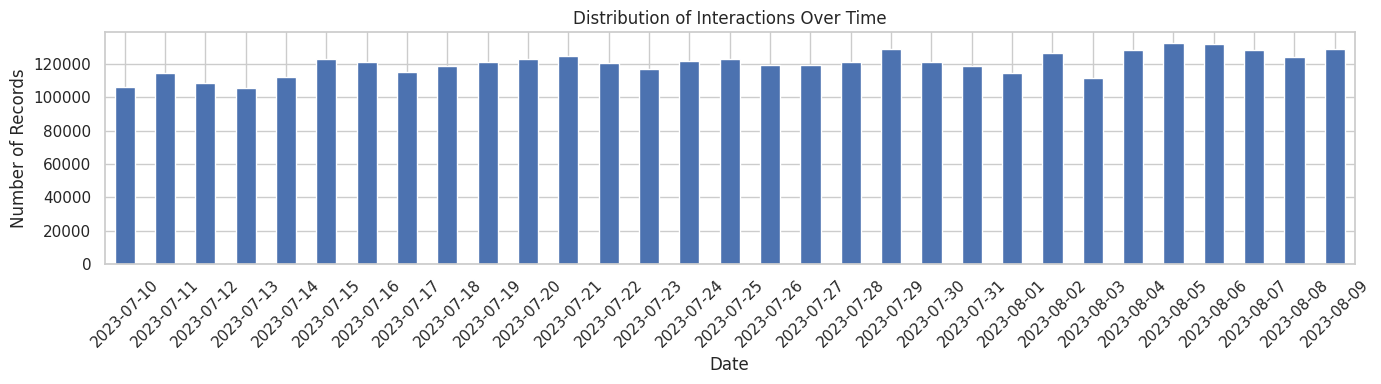

In [ ]:
# Convert log_time to datetime
df_all['log_time'] = pd.to_datetime(df_all['log_time'], errors='coerce')

# Plot distribution over time
df_all['log_time'].dt.date.value_counts().sort_index().plot(kind='bar', figsize=(14,4))
plt.title("Distribution of Interactions Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(True)
plt.show()

#### Scene Analysis

In [ ]:
scene_counts = df_all['scene'].value_counts().sort_index()
print("Scenario distribution:")
print(scene_counts)

Scenario distribution:
scene
0     217611
1     918442
2    1900034
3     423105
4     271137
Name: count, dtype: int64


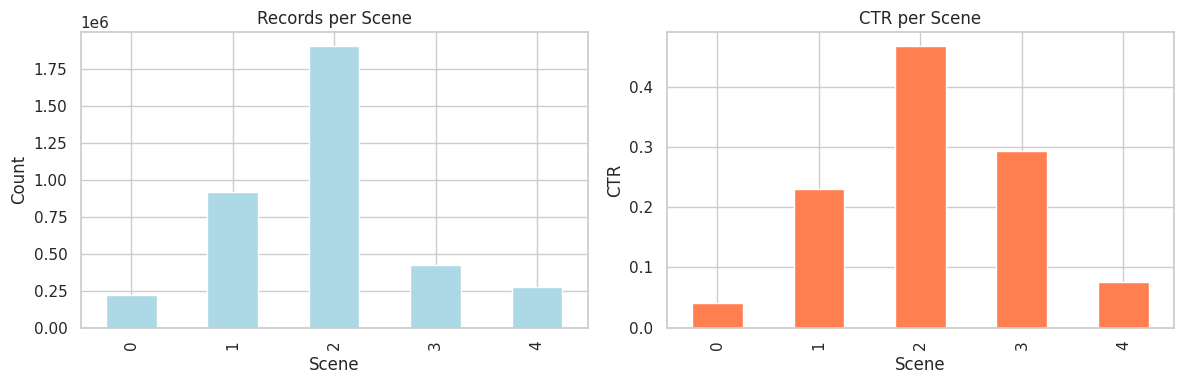

In [ ]:
scene_ctr = df_all.groupby('scene')['label'].mean().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

scene_counts.plot(kind='bar', ax=ax[0], color='lightblue')
ax[0].set_title("Records per Scene")
ax[0].set_xlabel("Scene")
ax[0].set_ylabel("Count")

scene_ctr.plot(kind='bar', ax=ax[1], color='coral')
ax[1].set_title("CTR per Scene")
ax[1].set_xlabel("Scene")
ax[1].set_ylabel("CTR")

plt.tight_layout()
plt.show()


Label distribution:
label
0    2475695
1    1254634
Name: count, dtype: int64
Overall CTR: 33.63%


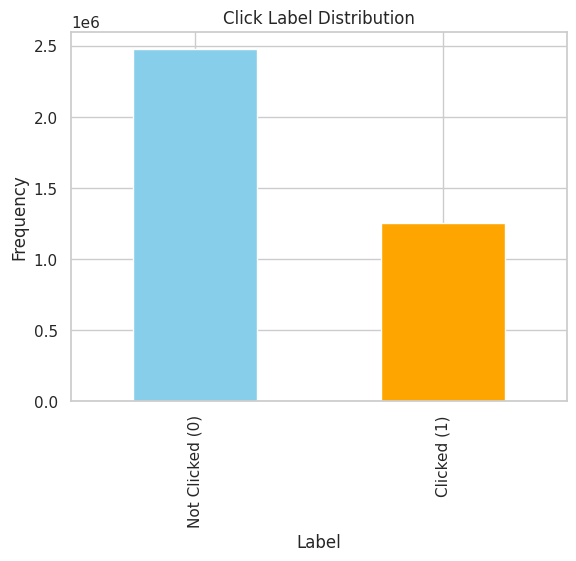

In [ ]:
# Clicked vs Not Clicked
label_counts = df_all['label'].value_counts().sort_index()
print("Label distribution:")
print(label_counts)

# CTR
ctr = label_counts[1] / label_counts.sum()
print(f"Overall CTR: {ctr:.2%}")

# Bar plot
label_counts.plot(kind="bar", color=["skyblue", "orange"])
plt.xticks([0, 1], ["Not Clicked (0)", "Clicked (1)"])
plt.title("Click Label Distribution")
plt.xlabel("Label")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()